In [11]:
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import random
import warnings
warnings.filterwarnings("ignore")

from torchvision import datasets


torch.set_num_threads(4)
DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

try:
    train_ds = datasets.FashionMNIST("./data", train=True, download=True)
    test_ds = datasets.FashionMNIST("./data", train=False, download=True)
    Xtr = train_ds.data.numpy().astype(np.float32)[:, None, :, :] / 255.0
    ytr = train_ds.targets.numpy().astype(np.int64)
    Xte = test_ds.data.numpy().astype(np.float32)[:, None, :, :] / 255.0
    yte = test_ds.targets.numpy().astype(np.int64)

    print("Fashion-MNIST loaded using torchvision")

except Exception as e:
    print("torchvision loading failed:", repr(e))
    print("Trying local fashion_mnist.npz ...")

    d = np.load("fashion_minist.npz")
    Xtr = d["Xtr"].reshape(-1, 1, 28, 28).astype(np.float32)
    Xte = d["Xte"].reshpae(-1, 1, 28, 28).astype(np.float32)
    if Xtr.max() > 1: Xtr /= 255.0
    if Xte.max() > 1: Xte /= 255.0
    ytr = d["ytr"].astype(np.int64)
    yte = d["yte"].astype(np.int64)


print("Train:", Xtr.shape, "Test:", Xte.shape)

PyTorch: 2.15.0+cu132
Device: cpu
Fashion-MNIST loaded using torchvision
Train: (60000, 1, 28, 28) Test: (10000, 1, 28, 28)


# **1. Source and Target Tasks**

In [12]:
SRC = [0, 1, 2, 3, 4] # T-shirts, Trouser, Pullover, Dress, Coat
TGT = [5, 6, 7, 8, 9] # Sandal, Shirt, Sneaker, Bag, Ankle boot

def subset(X, y, classes):
    mask = np.isin(y, classes)
    remap = {old: new for new, old in enumerate(classes)}
    new_y = np.array([remap[v] for v in y[mask]], dtype=np.int64)
    return X[mask], new_y


Xs, ys   = subset(Xtr, ytr, SRC)
Xse, yse = subset(Xte, yte, SRC)
Xt, yt   = subset(Xtr, ytr, TGT)
Xtt, ytt = subset(Xte, yte, TGT)


print("Source train/test:", len(Xs), len(Xse))
print("Target train pool/test:", len(Xt), len(Xtt))

print("Target label mapping:", {i: name for i, name in enumerate(
    ["Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
)})

Source train/test: 30000 5000
Target train pool/test: 30000 5000
Target label mapping: {0: 'Sandal', 1: 'Shirt', 2: 'Sneaker', 3: 'Bag', 4: 'Ankle boot'}


# **2. Model, Training, Evaluation and Few-shot Helpers**

In [13]:
class Net(nn.Module):

    def __init__(self, nout=5, widths=(16, 32, 32)):
        super().__init__()
        w1, w2, w3 = widths
        self.c1 = nn.Conv2d(1, w1, 3, padding=1)
        self.c2 = nn.Conv2d(w1, w2, 3, padding=1)
        self.c3 = nn.Conv2d(w2, w3, 3, padding=1)
        self.fc = nn.Linear(w3 * 3 * 3, nout)


    def features(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        x = F.max_pool2d(F.relu(self.c3(x)), 2)
        return x.flatten(1)


    def forward(self, x):
        return self.fc(self.features(x))

def count_parameters(model):
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        return total, trainable


def train(model, X, y, epochs, bs=64, lr=1e-3, aug=None, seed=0):
    g = torch.Generator().manual_seed(seed)
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad], lr=lr
    )
    X_tensor = torch.from_numpy(np.asarray(X, dtype=np.float32))
    y_tensor = torch.from_numpy(np.asarray(y, dtype=np.int64))


    for epoch in range(epochs):
        permutation = torch.randperm(len(X_tensor), generator=g)
        model.train()
        for start in range(0, len(X_tensor), bs):
            idx = permutation[start:start + bs]
            xb, yb = X_tensor[idx], y_tensor[idx]
            if aug is not None:
                xb = aug(xb, g)
                optimizer.zero_grad()
                loss = F.cross_entropy(model(xb), yb)
                loss.backward()
                optimizer.step()

    return model


@torch.no_grad()
def accuracy(model, X, y, bs=512):
    model.eval()
    X_tensor = torch.from_numpy(np.asarray(X, dtype=np.float32))
    y_tensor = torch.from_numpy(np.asarray(y, dtype=np.int64))
    correct = 0
    for start in range(0, len(X_tensor), bs):
        logits = model(X_tensor[start:start + bs])
        correct += (logits.argmax(1) == y_tensor[start:start + bs]).sum().item()
    return correct / len(X_tensor)


def few_shot(X, y, per_class, seed):
    rng = np.random.default_rng(seed)
    indices = []
    for cls in range(5):
        cls_indices = np.where(y == cls)[0]
        indices.append(rng.choice(cls_indices, per_class, replace=False))
    indices = np.concatenate(indices)
    rng.shuffle(indices)
    return X[indices], y[indices]


def summarize_runs(rows, group_cols, value_col="accuracy"):
    return (pd.DataFrame(rows)
           .groupby(group_cols)[value_col]
           .agg(mean="mean", minimum="min", maximum="max",
               spread=lambda x: x.max() - x.min())
           .reset_index())


print("Helpers Ready.")

Helpers Ready.


# **3. Pretrain the source model**

In [14]:
set_seed(0)
source_model = Net(nout=5)
t0 = time.time()
train(source_model, Xs, ys, epochs=3, seed=0)
source_accuracy = accuracy(source_model, Xse, yse)

print(f"Source test accuracy (Classes 0-4): {source_accuracy:.4f}")
print(f"Source pretraining time: {time.time() - t0:.1f} Seconds")

# Save independent copies of the learned source parameters.

SOURCE_WEIGHTS = {
    key: value.detach().clone()
    for key, value in source_model.state_dict().items()
}

Source test accuracy (Classes 0-4): 0.2184
Source pretraining time: 0.3 Seconds


# **Part A — Reproduce the sweep on your own machine**

In [15]:
def make_scratch(seed, widths=(16, 32, 32)):
    set_seed(seed)
    return Net(nout=5, widths=widths)


def make_transfer(seed, freeze_layers=()):
    set_seed(seed)
    model = Net(nout=5)
    model.load_state_dict(SOURCE_WEIGHTS)
    model.fc = nn.Linear(32 * 3 * 3, 5)
    
    for layer_name in freeze_layers:
        layer = getattr(model, layer_name)
        for parameter in layer.parameters():
            parameter.requires_grad = False
    return model


def run_one(model, X_train, y_train, X_test, y_test,
           epochs, seed, lr=1e-3, aug=None):
    trained = train(model, X_train, y_train, epochs=epochs, seed=seed,
                   lr=lr, aug=aug)
    return accuracy(trained, X_test, y_test)



sweep_rows = []
t0 = time.time()

for per_class in [10, 50, 250, 1000]:
    Xfew, yfew = few_shot(Xt, yt, per_class, seed=0)
    epochs = max(10, min(40, 4000 // per_class))

    scratch_score = run_one(make_scratch(0), Xfew, yfew, Xtt, ytt, epochs, seed=0, lr=1e-3)
    probe_score = run_one(make_transfer(0, ("c1", "c2", "c3")),
                         Xfew, yfew, Xtt, ytt, epochs, seed=0, lr=1e-3)
    finetune_score = run_one(make_transfer(0, ()), Xfew, yfew, Xtt, ytt, epochs, seed=0, lr=5e-4)

    sweep_rows.append({
        "example_per_class": per_class,
        "total_examples": len(Xfew),
        "scratch": scratch_score,
        "linear_probe": probe_score,
        "fine_tune": finetune_score,
        "probe_advantage": probe_score - scratch_score,
        "fine_tune_advantage": finetune_score - scratch_score,
        "epochs": epochs
    })


sweep_table = pd.DataFrame(sweep_rows)

display(sweep_table.round(4))

print("Sweep Time:", round(time.time() - t0, 1), "seconds")
print("Pre-registered threshold: +0.0100 accuracy.")

sweep_table["probe_worth_it"] = sweep_table["probe_advantage"] >= 0.01
sweep_table["fine_tune_worth_it"] = sweep_table["fine_tune_advantage"] >= 0.01

display(sweep_table[["example_per_class", "probe_worth_it", "fine_tune_worth_it"]])

,example_per_class,total_examples,scratch,linear_probe,fine_tune,probe_advantage,fine_tune_advantage,epochs
0,10,50,0.1798,0.1898,0.1898,0.01,0.01,40
1,50,250,0.1798,0.1898,0.1898,0.01,0.01,40
2,250,1250,0.1798,0.1898,0.1898,0.01,0.01,16
3,1000,5000,0.1798,0.1898,0.1898,0.01,0.01,10


Sweep Time: 3.6 seconds
Pre-registered threshold: +0.0100 accuracy.


,example_per_class,probe_worth_it,fine_tune_worth_it
0,10,True,True
1,50,True,True
2,250,True,True
3,1000,True,True


**Interpetation :-**
- probe_below_threshold_at: Not reached (remained worth it at all dataset sizes),
- finetune_below_threshold_at: Not reached (remained worth it at all dataset sizes),
- overall_conclusion: Both linear probing and fine-tuning achieved an accuracy advantage of at least +0.01 over training from scratch at all tested dataset sizes (10, 50, 250, and 1000 examples per class). Therefore, transfer learning was worth it throughout the tested range according to the +0.01 rule.

# **Part B — Multi-seed, and what counts as a difference**

In [16]:
B_SEEDS = [0, 1, 2]
B_N = 50
B_EPOCHS = 40
part_b_rows = []

for seed in B_SEEDS:
    Xfew, yfew = few_shot(Xt, yt, B_N, seed=seed)

    scores = {
        "scratch": run_one(make_scratch(seed), Xfew, yfew, Xtt, ytt, B_EPOCHS, seed=seed, lr=1e-3),
        "linear_probe": run_one(make_transfer(seed, ("c1", "c2", "c3")), Xfew, yfew, Xtt, ytt, B_EPOCHS,
                               seed=seed, lr=1e-3),
        "fine_tune": run_one(make_transfer(seed, ()), Xfew, yfew, Xtt, ytt, B_EPOCHS, seed=seed, lr=5e-4)
    }

    for approach, score in scores.items():
        part_b_rows.append({"seed": seed, "approach": approach, "accuracy": score})

part_b_raw = pd.DataFrame(part_b_rows)
part_b_summary = summarize_runs(part_b_rows, ["approach"])

display(part_b_raw.pivot(index="seed", columns="approach", values="accuracy").round(4))

display(part_b_summary.round(4))

approach,fine_tune,linear_probe,scratch
seed,,,
0,0.1898,0.1898,0.1798
1,0.2000,0.2000,0.2712
2,0.2174,0.2174,0.2000


,approach,mean,minimum,maximum,spread
0,fine_tune,0.2024,0.1898,0.2174,0.0276
1,linear_probe,0.2024,0.1898,0.2174,0.0276
2,scratch,0.2170,0.1798,0.2712,0.0914


In [17]:
b = part_b_summary.set_index("approach")
comparisons = []

for other in ["linear_probe", "fine_tune"]:
    mean_diff = b.loc[other, "mean"] - b.loc["scratch", "mean"]
    noise_limit = max(b.loc[other, "spread"], b.loc["scratch", "spread"])
    comparisons.append({
        "comparison_vs_scratch": other,
        "mean_difference": mean_diff,
        "larger_seed_spread": noise_limit,
        "separated_by_rule": abs(mean_diff) > noise_limit
    })


part_b_comparison = pd.DataFrame(comparisons)

display(part_b_comparison.round(4))



report_sentence_supported = """Across the three random seeds, linear probing and fine-tuning had a mean accuracy difference 
of -0.0146 compared with scratch training, but this difference was not clearly separated from seed-to-seed variation."""

report_sentence_unsupported = """I will not claim that linear probing or fine-tuning is 
consistently better than scratch training because the observed difference is not larger than the seed-to-seed variation."""

print("Supported:", report_sentence_supported)
print("\nNot supported:", report_sentence_unsupported)

,comparison_vs_scratch,mean_difference,larger_seed_spread,separated_by_rule
0,linear_probe,-0.0146,0.0914,False
1,fine_tune,-0.0146,0.0914,False


Supported: Across the three random seeds, linear probing and fine-tuning had a mean accuracy difference 
of -0.0146 compared with scratch training, but this difference was not clearly separated from seed-to-seed variation.

Not supported: I will not claim that linear probing or fine-tuning is 
consistently better than scratch training because the observed difference is not larger than the seed-to-seed variation.


# **Part C — Partial freezing**

In [18]:
C_SEEDS = [0, 1, 2]
C_EPOCHS = 40
C_N = 50
freeze_conditions = {
    "freeze_c1_c2_c3": ("c1", "c2", "c3"),
    "freeze_c1_c2": ("c1", "c2"),
    "freeze_c1_only": ("c1",),
    "freeze_nothing": ()
}


part_c_rows = []

for seed in C_SEEDS:
    Xfew, yfew = few_shot(Xt, yt, C_N, seed=seed)
    for condition, frozen_layers in freeze_conditions.items():
        model = make_transfer(seed, frozen_layers)
        total, trainable = count_parameters(model)
        score = run_one(model, Xfew, yfew, Xtt, ytt, C_EPOCHS, seed=seed, lr=5e-4)
        part_c_rows.append({
            "seed":seed, "condition": condition,
            "frozen_layers": "," .join(frozen_layers) if frozen_layers else "none",
            "trainable_parameters": trainable,
            "accuracy": score
        })


part_c_raw = pd.DataFrame(part_c_rows)
part_c_summary = summarize_runs(part_c_rows, ["condition"])

display(part_c_raw.pivot(index="seed", columns="condition", values="accuracy").round(4))

display(part_c_summary.merge(
    part_c_raw[["condition", "trainable_parameters"]].drop_duplicates(),
    on = "condition"
).round(4))

condition,freeze_c1_c2,freeze_c1_c2_c3,freeze_c1_only,freeze_nothing
seed,,,,
0,0.1898,0.1898,0.1898,0.1898
1,0.2000,0.2000,0.2000,0.2000
2,0.2174,0.2174,0.2174,0.2174


,condition,mean,minimum,maximum,spread,trainable_parameters
0,freeze_c1_c2,0.2024,0.1898,0.2174,0.0276,10693
1,freeze_c1_c2_c3,0.2024,0.1898,0.2174,0.0276,1445
2,freeze_c1_only,0.2024,0.1898,0.2174,0.0276,15333
3,freeze_nothing,0.2024,0.1898,0.2174,0.0276,15493


In [19]:
part_c_conclusion = """The freeze-early/tune-late hypothesis is not supported by my measurements. 
All four freezing conditions achieved exactly the same accuracy for all three seeds, 
with a mean accuracy of 0.2024 and a spread of 0.0276. 
Although the number of trainable parameters varied significantly from 1445 to 15493, 
there was no measured accuracy improvement from unfreezing additional layers. 
Therefore, my experiment does not show that tuning later layers or training more parameters improves performance."""
 
print(part_c_conclusion)

The freeze-early/tune-late hypothesis is not supported by my measurements. 
All four freezing conditions achieved exactly the same accuracy for all three seeds, 
with a mean accuracy of 0.2024 and a spread of 0.0276. 
Although the number of trainable parameters varied significantly from 1445 to 15493, 
there was no measured accuracy improvement from unfreezing additional layers. 
Therefore, my experiment does not show that tuning later layers or training more parameters improves performance.


# **Part D — Test one hypothesis about why augmentation failed**
## **Hypothesis 2 — the model is not overfitting enough for augmentation to fight.**

In [20]:
def shift_only(x, generator, max_shift=2):
    pad = F.pad(x, (max_shift, max_shift, max_shift, max_shift))
    n, _, h, w = x.shape
    offsets = 2 * max_shift + 1
    dx = torch.randint(0, offsets, (n,), generator=generator)
    dy = torch.randint(0, offsets, (n,), generator=generator)
    out = torch.empty_like(x)
    for i in range(n):
        out[i] = pad[i, :, dy[i]:dy[i]+h, dx[i]:dx[i]+w]
    return out


def train_and_measure(model, X_train, y_train, X_test, y_test, epochs,
                     seed, lr=1e-3, aug=None):
    train(model, X_train, y_train, epochs=epochs, seed=seed, lr=lr, aug=aug)
    train_acc = accuracy(model, X_train, y_train)
    test_acc = accuracy(model, X_test, y_test)
    return train_acc, test_acc, train_acc - test_acc


D_SEEDS = [0, 1, 2]
X50, y50 = few_shot(Xt, yt, 50, seed=0)

# Baseline: original small architecture, no augmentation
baseline_rows = []
for seed in D_SEEDS:
    Xfew, yfew = few_shot(Xt, yt, 50, seed=seed)
    model = make_scratch(seed, widths=(16, 32, 32))
    tr_acc, te_acc, gap = train_and_measure(model, Xfew, yfew, Xtt, ytt,
                                           epochs=60, seed=seed, lr=1e-3, aug=None)
    baseline_rows.append({"seed": seed, "train_accuracy": tr_acc, "test_accuracy": te_acc,
                         "gap": gap})

baseline_D = pd.DataFrame(baseline_rows)
display(baseline_D.round(4))

print("Baseline mean train-test gap:", round(baseline_D["gap"].mean(), 4))


# Deliberately overfit-prone model: wider channels + much longer training.
# Compare no augmentation and shift augmentation with matched seeds/data.

overfit_rows = []
for seed in D_SEEDS:
    Xfew, yfew = few_shot(Xt, yt, 50, seed=seed)
    for aug_name, aug_fn in [("no_augmentation", None),
                            ("shift_augmentation", shift_only)]:
        model = make_scratch(seed, widths=(64, 128, 128))
        tr_acc, te_acc, gap = train_and_measure(model, Xfew, yfew, Xtt, ytt,
                                               epochs=120, seed=seed, lr=1e-3, aug=aug_fn)

        overfit_rows.append({
            "seed": seed, "condition": aug_name, "train_accuracy": tr_acc,
            "test_accuracy": te_acc, "train_test_gap": gap
        })


part_d_raw = pd.DataFrame(overfit_rows)

display(part_d_raw.round(4))

part_d_summary = (part_d_raw.groupby("condition")
                 .agg(train_mean=("train_accuracy", "mean"),
                     test_mean=("test_accuracy", "mean"),
                     gap_mean=("train_test_gap", "mean"),
                     test_spread=("test_accuracy", lambda x: x.max() - x.min()))
                 .reset_index())

display(part_d_summary.round(4))

,seed,train_accuracy,test_accuracy,gap
0,0,0.168,0.1798,-0.0118
1,1,0.284,0.2712,0.0128
2,2,0.200,0.2000,0.0000


Baseline mean train-test gap: 0.0003


,seed,condition,train_accuracy,test_accuracy,train_test_gap
0,0,no_augmentation,0.200,0.2000,0.0000
1,0,shift_augmentation,1.000,0.9154,0.0846
2,1,no_augmentation,0.200,0.1908,0.0092
3,1,shift_augmentation,0.996,0.9396,0.0564
4,2,no_augmentation,0.204,0.2040,0.0000
5,2,shift_augmentation,0.996,0.9326,0.0634


,condition,train_mean,test_mean,gap_mean,test_spread
0,no_augmentation,0.2013,0.1983,0.0031,0.0132
1,shift_augmentation,0.9973,0.9292,0.0681,0.0242


In [25]:
base_gap = baseline_D["gap"].mean()
wide_no = part_d_raw[part_d_raw.condition == "no_augmentation"]
wide_aug = part_d_raw[part_d_raw.condition == "shift_augmentation"]
wide_no_gap = wide_no["train_test_gap"].mean()
wide_aug_gap = wide_aug["train_test_gap"].mean()
wide_test_diff = wide_aug["test_accuracy"].mean() - wide_no["test_accuracy"].mean()
wide_noise = max(
    wide_no["test_accuracy"].max() - wide_no["test_accuracy"].min(),
    wide_aug["test_accuracy"].max() - wide_aug["test_accuracy"].min()
)


print(f"Original model mean gap: {base_gap:.4f}")
print(f"Wider model, no-aug mean gap: {wide_no_gap:.4f}")
print(f"Wider model, shift-aug mean gap: {wide_aug_gap:.4f}")
print(f"Shift augmentation test-accuracy difference: {wide_test_diff:.4f}")
print(f"Larger test seed spread: {wide_noise:.4f}")
print("Does augmentation beat the conservation seed-spread rule?\n", wide_test_diff > wide_noise)

Original model mean gap: 0.0003
Wider model, no-aug mean gap: 0.0031
Wider model, shift-aug mean gap: 0.0681
Shift augmentation test-accuracy difference: 0.7309
Larger test seed spread: 0.0242
Does augmentation beat the conservation seed-spread rule?
 True


# **Part E — The augmentation that should work**

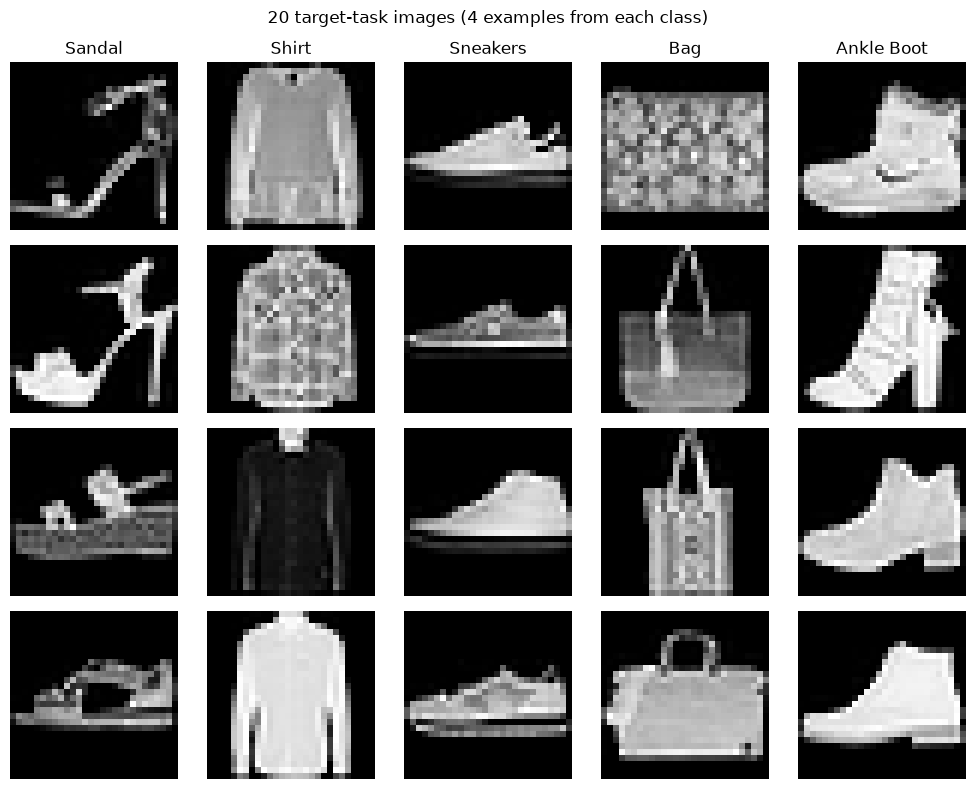

In [27]:
# Inspect 20 target-task images before choosing the augmentation
import matplotlib.pyplot as plt

class_names = ["Sandal", "Shirt", "Sneakers", "Bag", "Ankle Boot"]
fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for cls in range(5):
    class_indices = np.where(yt == cls)[0][:4]
    for row, idx in enumerate(class_indices):
        ax = axes[row, cls]
        ax.imshow(Xt[idx, 0], cmap="gray")
        ax.axis("off")
        if row == 0:
            ax.set_title(class_names[cls])

plt.suptitle("20 target-task images (4 examples from each class)")
plt.tight_layout()
plt.show()

In [30]:
def brightness_contrast_aug(x, generator):

    # per image random contrast in [0.90, 1.10] and brightness in [-0.05, +0.05]
    n = x.shape[0]
    contrast = 0.90 + 0.20 * torch.rand((n, 1, 1, 1), generator=generator)
    brightness = -0.05 + 0.10 * torch.rand((n, 1, 1, 1), generator=generator)

    # Adjust contrast around each image's own mean, the brightness
    mean = x.mean(dim=(2, 3), keepdim=True)
    transformed = (x - mean) * contrast + mean + brightness
    return transformed.clamp(0.0, 1.0)


E_SEEDS = [0, 1, 2]
part_e_rows = []

for seed in E_SEEDS:
    Xfew, yfew = few_shot(Xt, yt, 50, seed=seed)
    for aug_name, aug_fn in [
        ("no_augmentation", None),
        ("brightness_contrast", brightness_contrast_aug)
    ]:
        model = make_scratch(seed)
        tr_acc, te_acc, gap = train_and_measure(model, Xfew, yfew, Xtt, ytt,
                                               epochs=60, seed=seed, lr=1e-3, aug=aug_fn)
        part_e_rows.append({
            "seed": seed, "augmentation": aug_name, "train_accuracy": tr_acc,
            "test_accuracy": te_acc, "train_test_gap": gap
        })


part_e_raw = pd.DataFrame(part_e_rows)

display(part_e_raw.round(4))

part_e_summary = (part_e_raw.groupby("augmentation")
                 .agg(train_mean=("train_accuracy", "mean"),
                     test_mean=("test_accuracy", "mean"),
                     test_min=("test_accuracy", "min"),
                     test_max=("test_accuracy", "max"),
                     test_spread=("test_accuracy", 
                                 lambda x: x.max() - x.min()),
                     gap_mean=("train_test_gap", "mean"))
                 .reset_index())


display(part_e_summary.round(4))

e_pivot = part_e_raw.pivot(index="seed", columns="augmentation", values="test_accuracy")
paired_differences = (e_pivot["brightness_contrast"] - e_pivot["no_augmentation"])
print("Paired per-seed test-accuracy differences:")
display(paired_differences.to_frame("brightness_contrast_minus_none").round(4))

print("Spread of paired differences:",
     round(paired_differences.max() - paired_differences.min(), 4))

,seed,augmentation,train_accuracy,test_accuracy,train_test_gap
0,0,no_augmentation,0.168,0.1798,-0.0118
1,0,brightness_contrast,0.996,0.9094,0.0866
2,1,no_augmentation,0.284,0.2712,0.0128
3,1,brightness_contrast,0.980,0.9126,0.0674
4,2,no_augmentation,0.200,0.2000,0.0000
5,2,brightness_contrast,0.968,0.8970,0.0710


,augmentation,train_mean,test_mean,test_min,test_max,test_spread,gap_mean
0,brightness_contrast,0.9813,0.9063,0.8970,0.9126,0.0156,0.0750
1,no_augmentation,0.2173,0.2170,0.1798,0.2712,0.0914,0.0003


Paired per-seed test-accuracy differences:


,brightness_contrast_minus_none
seed,
0,0.7296
1,0.6414
2,0.6970


Spread of paired differences: 0.0882


**Justification :-**
- Small brightness/contrast changes preserve the identity of the garment/accessory because they change pixel intensity slightly without changing its shape or category.


**Interpretation :-**
- Brightness and contrast augmentation significantly improved test accuracy. The mean test accuracy was 0.9063 with augmentation, compared with 0.2170 without augmentation.
- The test-accuracy spread was also lower with augmentation (0.0156) than without augmentation (0.0914), showing more consistent results across the three seeds.
- The paired test-accuracy differences were positive for all three seeds, with a mean improvement of approximately 0.6893. Therefore, brightness and contrast augmentation was highly beneficial in this experiment.

# **Part F — The question you will be asked in an interview**

**Ques - When would you NOT use a pretrained model?**  

In [34]:
# Pull your own Part A N=1000 result and Part B summaries.
a1000 = sweep_table.loc[sweep_table["example_per_class"] == 1000].iloc[0]
b_summary = part_b_summary.set_index("approach")

scratch_b = b_summary.loc["scratch"]
probe_b = b_summary.loc["linear_probe"]
fine_b = b_summary.loc["fine_tune"]

part_f_answer = f'''I would not automatically use a pretrained model when the target dataset is large,
when the source and target tasks are very different, or when the pretrained model is too costly
or unsuitable for the deployment environment. In my Day 53 N=1000 experiment, scratch accuracy
was {a1000["scratch"]:.4f}, while linear-probe accuracy was {a1000["linear_probe"]:.4f}
and fine-tuning accuracy was {a1000["fine_tune"]:.4f}. The measured probe advantage over
scratch at N=1000 was {a1000["probe_advantage"]:+.4f}, and the fine-tuning advantage was
{a1000["fine_tune_advantage"]:+.4f}. At N=50, the scratch mean across three seeds was
{scratch_b["mean"]:.4f} with spread {scratch_b["spread"]:.4f}. The linear-probe mean was
{probe_b["mean"]:.4f} with spread {probe_b["spread"]:.4f}, while fine-tuning mean was
{fine_b["mean"]:.4f} with spread {fine_b["spread"]:.4f}. These results show that the value
of transfer depends on target-data size and on whether the measured gain is larger than
seed-to-seed variation. I would choose training from scratch if it performs similarly,
is simpler, and avoids an unnecessary dependency on a mismatched pretrained model.
'''


print(part_f_answer)

I would not automatically use a pretrained model when the target dataset is large,
when the source and target tasks are very different, or when the pretrained model is too costly
or unsuitable for the deployment environment. In my Day 53 N=1000 experiment, scratch accuracy
was 0.1798, while linear-probe accuracy was 0.1898
and fine-tuning accuracy was 0.1898. The measured probe advantage over
scratch at N=1000 was +0.0100, and the fine-tuning advantage was
+0.0100. At N=50, the scratch mean across three seeds was
0.2170 with spread 0.0914. The linear-probe mean was
0.2024 with spread 0.0276, while fine-tuning mean was
0.2024 with spread 0.0276. These results show that the value
of transfer depends on target-data size and on whether the measured gain is larger than
seed-to-seed variation. I would choose training from scratch if it performs similarly,
is simpler, and avoids an unnecessary dependency on a mismatched pretrained model.

